# Synthetic Data Generation using FairGAN

This notebook implements a FairGAN model to generate synthetic data.

The objective is to compare FairGAN with non-fair models in terms of:
- Data quality
- Preservation of statistical properties
- Fairness across sensitive attributes

In [32]:
import pandas as pd
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

## Dataset

We use the Adult Income dataset which is our test data.

In [33]:
df = pd.read_csv("test_data/adult.csv")

df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Data Preprocessing

We define categorical variables and clean the dataset.

In [34]:
df = df.replace('?', np.nan).dropna()
df.columns = [col.strip() for col in df.columns]

# Encode categorical variables
df_encoded = df.copy()

for col in df_encoded.columns:
    if df_encoded[col].dtype == 'object':
        df_encoded[col] = LabelEncoder().fit_transform(df_encoded[col])

### Define Sensitive and Target

In [35]:
S = 'sex'
Y = 'income'

S_index = df_encoded.columns.get_loc(S)
Y_index = df_encoded.columns.get_loc(Y)

## FairGAN Model
### Model Architecture

FairGAN consists of:
- Generator
- Discriminator
- Fairness discriminator

In [36]:
input_dim = df_encoded.shape[1]
noise_dim = 100

#Generator
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(noise_dim, 128),
            nn.ReLU(),
            nn.Linear(128, input_dim)
        )

    def forward(self, z):
        return self.model(z)
    

# Real/Fake Discriminator (D1)
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

# Fairness Discriminator (D2)
class FairnessDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)    

### Model Initialization

In [37]:
G = Generator()
D1 = Discriminator()
D2 = FairnessDiscriminator()

criterion = nn.BCELoss()

g_optimizer = optim.Adam(G.parameters(), lr=0.001)
d1_optimizer = optim.Adam(D1.parameters(), lr=0.001)
d2_optimizer = optim.Adam(D2.parameters(), lr=0.001)

data = torch.tensor(df_encoded.values, dtype=torch.float32)

epochs = 200
lambda_fair = 0.05 

## FairGAN Model Training

In [38]:
for epoch in range(epochs):

    # Train D1 (real vs fake)
    real_labels = torch.ones(len(data), 1)
    fake_labels = torch.zeros(len(data), 1)

    z = torch.randn(len(data), noise_dim)
    fake_data = G(z)

    d1_real = D1(data)
    d1_fake = D1(fake_data.detach())

    d1_loss = criterion(d1_real, real_labels) + \
              criterion(d1_fake, fake_labels)

    d1_optimizer.zero_grad()
    d1_loss.backward()
    d1_optimizer.step()


    # Train D2 (predict S)
    S_real = data[:, S_index].unsqueeze(1)

    d2_pred = D2(data)
    d2_loss = criterion(d2_pred, S_real)

    d2_optimizer.zero_grad()
    d2_loss.backward()
    d2_optimizer.step()


    # Train Generator
    z = torch.randn(len(data), noise_dim)
    fake_data = G(z)


    #GAN loss (fool D1)
    g_loss = criterion(D1(fake_data), real_labels)

    #FAIRNESS loss (Xu-style)
    S_fake_pred = D2(fake_data)

    # push D2 to be uncertain (0.5)
    target_uncertain = torch.full_like(S_fake_pred, 0.5)
    fair_loss = criterion(S_fake_pred, target_uncertain)

    #TOTAL LOSS
    total_g_loss = g_loss - lambda_fair * fair_loss

    g_optimizer.zero_grad()
    total_g_loss.backward()
    g_optimizer.step()

    if epoch % 10 == 0:
        print(f"Epoch {epoch} | D1: {d1_loss.item():.4f} | D2: {d2_loss.item():.4f} | G: {g_loss.item():.4f} | Fair: {fair_loss.item():.4f}")

Epoch 0 | D1: 100.6922 | D2: 33.1518 | G: 0.7051 | Fair: 0.6956
Epoch 10 | D1: 100.6720 | D2: 33.1518 | G: 0.7293 | Fair: 0.6977
Epoch 20 | D1: 100.5624 | D2: 33.1518 | G: 0.8652 | Fair: 0.6994
Epoch 30 | D1: 100.4864 | D2: 33.1518 | G: 0.9728 | Fair: 0.6988
Epoch 40 | D1: 100.4742 | D2: 33.1518 | G: 0.9897 | Fair: 0.6974
Epoch 50 | D1: 100.4553 | D2: 33.1518 | G: 1.0280 | Fair: 0.6974
Epoch 60 | D1: 100.3765 | D2: 33.1518 | G: 1.1927 | Fair: 0.6967
Epoch 70 | D1: 100.2958 | D2: 33.1518 | G: 1.3986 | Fair: 0.6952
Epoch 80 | D1: 100.2958 | D2: 33.1518 | G: 1.3836 | Fair: 0.6952
Epoch 90 | D1: 100.3080 | D2: 33.1518 | G: 1.3444 | Fair: 0.6949
Epoch 100 | D1: 100.2611 | D2: 33.1518 | G: 1.4983 | Fair: 0.6939
Epoch 110 | D1: 100.2112 | D2: 33.1518 | G: 1.6882 | Fair: 0.6933
Epoch 120 | D1: 100.1866 | D2: 33.1518 | G: 1.7923 | Fair: 0.6933
Epoch 130 | D1: 100.1634 | D2: 33.1518 | G: 1.9113 | Fair: 0.6941
Epoch 140 | D1: 100.1425 | D2: 33.1518 | G: 2.0377 | Fair: 0.6956
Epoch 150 | D1: 100.1

## Synthetic Data Generation

In [39]:
z = torch.randn(len(data), noise_dim)
synthetic = G(z).detach().numpy()

fairgan_synthetic_data = pd.DataFrame(synthetic, columns=df_encoded.columns)

fairgan_synthetic_data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,0.105045,0.014384,-0.067055,0.040386,-0.011499,0.047796,-0.176263,0.087897,0.116918,0.185217,0.229996,-0.165621,-0.091181,0.069101,-0.087556
1,0.094920,-0.029019,-0.124031,0.059132,0.026110,0.042606,-0.399529,0.239516,0.167785,0.208855,0.326494,-0.174661,-0.122287,0.126074,-0.171680
2,-0.002676,-0.104560,-0.141106,0.134127,-0.047731,0.038946,-0.255025,0.198916,0.147554,0.158774,0.181778,-0.064968,-0.057370,-0.033431,0.055676
3,0.071447,-0.098543,-0.089360,0.123488,-0.037854,-0.006064,-0.256696,0.156321,0.149115,0.137436,0.210514,-0.103855,-0.006863,0.066264,0.012797
4,0.043475,-0.036792,-0.156755,0.134328,-0.058906,0.068305,-0.250735,0.178220,0.158954,0.222511,0.137635,-0.150126,-0.085897,0.048135,-0.095909


Export synthetic data for analysis

In [40]:
fairgan_synthetic_data.to_csv("fairgan_synthetic.csv", index=False)

## Distribution Comparison

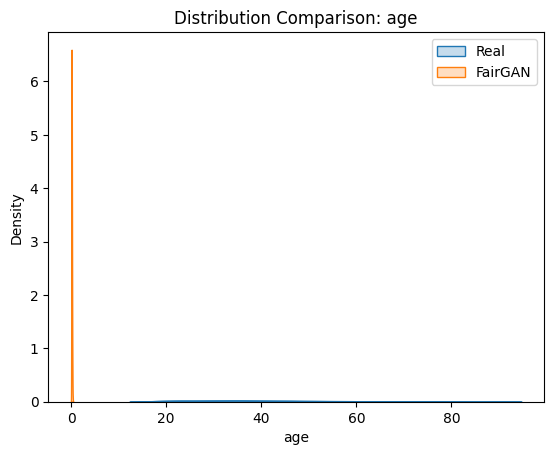

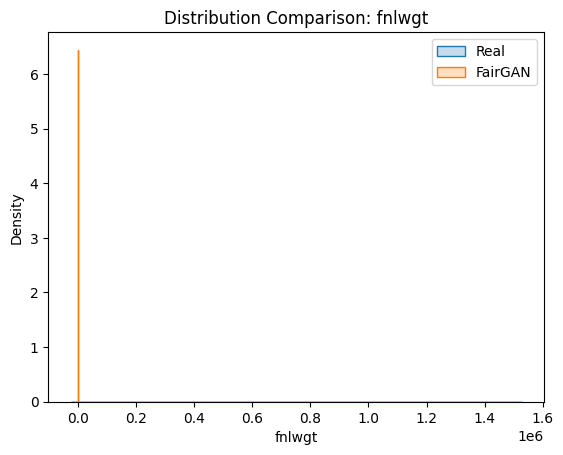

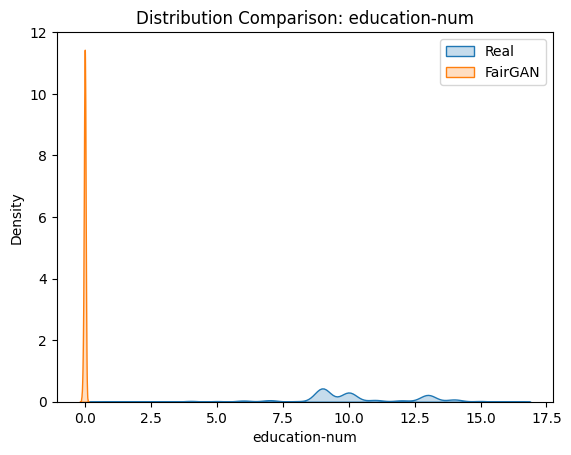

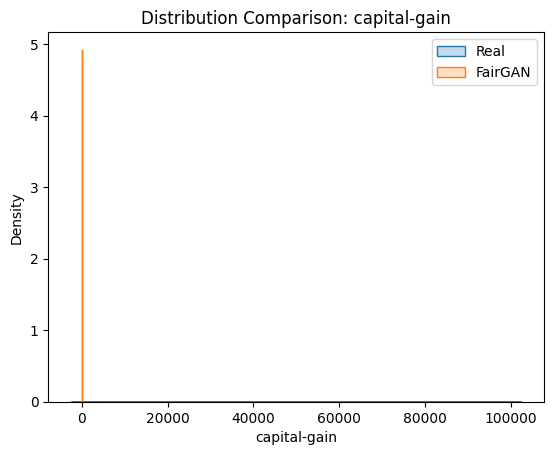

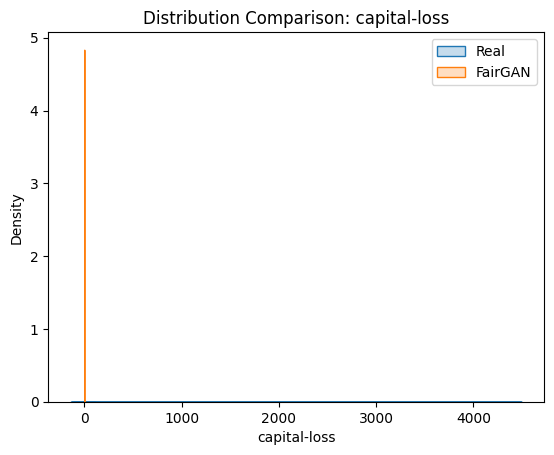

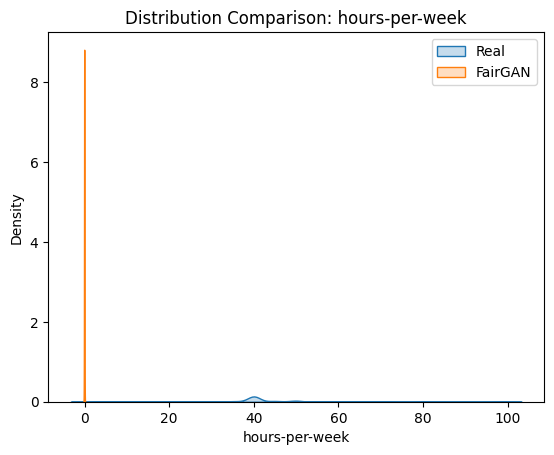

In [41]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numerical_cols:
    if col in fairgan_synthetic_data.columns: 
        plt.figure()
        
        sns.kdeplot(df[col], label="Real", fill=True)
        sns.kdeplot(fairgan_synthetic_data[col], label="FairGAN", fill=True)

        plt.title(f"Distribution Comparison: {col}")
        plt.legend()
        plt.show()

## Fairness Evaluation

In [42]:
#Convert income to binary
df['income_binary'] = df['income'].apply(lambda x: 1 if '>50K' in x else 0)
fairgan_synthetic_data['income_binary'] = (fairgan_synthetic_data['income'] > 0.5).astype(int)

df['sex_binary'] = df['sex'].apply(lambda x: 1 if 'Male' in x else 0)
fairgan_synthetic_data['sex_binary'] = (fairgan_synthetic_data['sex'] > 0.5).astype(int)

In [43]:
#Statistical Parity
def statistical_parity(df, sensitive_col, outcome_col):
    group_rates = df.groupby(sensitive_col)[outcome_col].mean()
    return group_rates.max() - group_rates.min(), group_rates

real_spd, real_rates = statistical_parity(df, 'sex_binary', 'income_binary')
fake_spd, fake_rates = statistical_parity(fairgan_synthetic_data, 'sex_binary', 'income_binary')

print("REAL SPD:", real_spd)
print(real_rates)

print("\nFAKE SPD (FairGAN):", fake_spd)
print(fake_rates)

REAL SPD: 0.19451574596420296
sex_binary
0    0.109251
1    0.303767
Name: income_binary, dtype: float64

FAKE SPD (FairGAN): 0.0
sex_binary
0    0.0
1    0.0
Name: income_binary, dtype: float64


In [44]:
print("Fake distribution:")
print(fairgan_synthetic_data["income_binary"].value_counts(normalize=True))

Fake distribution:
income_binary
0    1.0
Name: proportion, dtype: float64


In [45]:
#Disparity Gap
def disparate_impact(df, sensitive_col, outcome_col):
    group_rates = df.groupby(sensitive_col)[outcome_col].mean()
    return group_rates.min() / group_rates.max()

real_di = disparate_impact(df, 'sex_binary', 'income_binary')
fake_di = disparate_impact(fairgan_synthetic_data, 'sex_binary', 'income_binary')

print("REAL DI:", real_di)
print("FAKE DI (FairGAN):", fake_di)

REAL DI: 0.3596552625800337
FAKE DI (FairGAN): nan


/var/folders/2m/361556sx6lbc15sc52frn4j40000gn/T/ipykernel_57421/1265646003.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return group_rates.min() / group_rates.max()


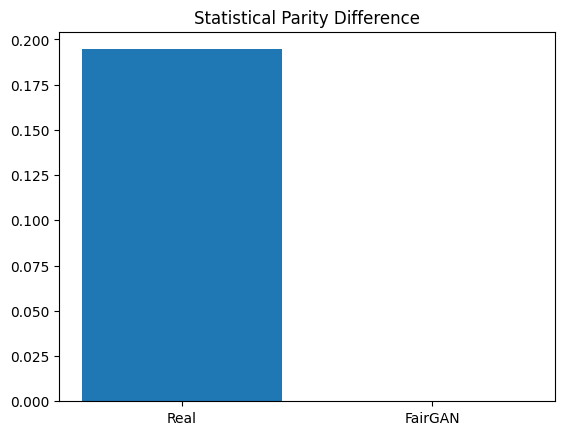

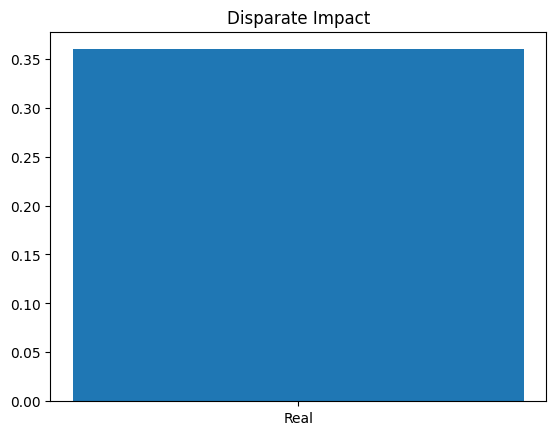

In [46]:
labels = ['Real', 'FairGAN']
spd_values = [real_spd, fake_spd]
di_values = [real_di, fake_di]

plt.figure()
plt.bar(labels, spd_values)
plt.title("Statistical Parity Difference")
plt.show()

plt.figure()
plt.bar(labels, di_values)
plt.title("Disparate Impact")
plt.show()